# Sentiment Classification of AI-Related Snippets (Sector-Year Evolution)

This notebook performs transformer-based sentiment classification on pre-extracted AI-related snippets and analyzes sentiment dynamics across sectors and years.

## Methodology (brief)

1. Load pre-built snippets from `data/snippets.csv`.
2. Standardize required fields (`snippet`, `year`, `sector`), deriving sector from company where needed.
3. Apply a transformer sentiment model to each snippet (batched, deduplicated, and accelerated when GPU/MPS is available).
4. Aggregate sentiment counts and shares by year and by sector-year.
5. Visualize results with line charts and heatmaps to track sentiment evolution over time.

Focus is on sector-level and overall temporal evolution, not single-company profiling.

In [ ]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from transformers import pipeline

In [ ]:
ROOT = Path.cwd()
SNIPPETS_PATH = ROOT / 'data' / 'snippets.csv'

df = pd.read_csv(SNIPPETS_PATH)
print('Loaded rows:', len(df))
df.head(3)

In [ ]:
if 'snippet' not in df.columns:
    candidates = [c for c in df.columns if c.lower() in {'text', 'content', 'sentence', 'context'}]
    if not candidates:
        raise ValueError('No snippet-like column found. Expected `snippet`.')
    df = df.rename(columns={candidates[0]: 'snippet'})

if 'year' not in df.columns:
    raise ValueError('Column `year` is required in data/snippets.csv.')

SECTOR_MAP = {
    'Nestlé S.A.': 'FMCG',
    'Unilever PLC': 'FMCG',
    'Procter & Gamble Co.': 'FMCG',
    'Colgate-Palmolive Co.': 'FMCG',
    'PepsiCo, Inc.': 'FMCG',
    'Ceconomy AG': 'Hardlines',
    'Electrolux AB': 'Hardlines',
    'The Home Depot, Inc.': 'Hardlines',
    'Kingfisher plc': 'Hardlines',
    'Whirlpool Corporation': 'Hardlines',
}

if 'sector' not in df.columns:
    if 'company' in df.columns:
        df['sector'] = df['company'].map(SECTOR_MAP).fillna('Unknown')
    else:
        df['sector'] = 'Unknown'

df['snippet'] = df['snippet'].astype(str).str.strip()
df['year'] = pd.to_numeric(df['year'], errors='coerce')
df = df[df['snippet'].str.len() > 0].copy()
df = df.dropna(subset=['year']).copy()
df['year'] = df['year'].astype(int)

print('Rows after cleaning:', len(df))
df[['snippet', 'year', 'sector']].head(3)

In [ ]:
try:
    import torch
    if torch.backends.mps.is_available():
        device = 0
    elif torch.cuda.is_available():
        device = 0
    else:
        device = -1
except Exception:
    device = -1

MODEL_NAME = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
clf = pipeline('sentiment-analysis', model=MODEL_NAME, device=device)

def normalize_label(raw_label: str) -> str:
    x = str(raw_label).upper()
    if x in {'LABEL_0', 'NEGATIVE', 'NEG'}:
        return 'Negative'
    if x in {'LABEL_1', 'NEUTRAL', 'NEU'}:
        return 'Neutral'
    if x in {'LABEL_2', 'POSITIVE', 'POS'}:
        return 'Positive'
    return str(raw_label).title()

def prep_text(x: str) -> str:
    return str(x).strip()[:1200]

start = perf_counter()
unique_snippets = df['snippet'].map(prep_text).drop_duplicates().tolist()
BATCH_SIZE = 64 if device != -1 else 24
pred_map = {}

for i in range(0, len(unique_snippets), BATCH_SIZE):
    batch = unique_snippets[i:i+BATCH_SIZE]
    out = clf(batch, truncation=True)
    if isinstance(out, dict):
        out = [out]
    for txt, pred in zip(batch, out):
        pred_map[txt] = (normalize_label(pred['label']), float(pred['score']))

cleaned = df['snippet'].map(prep_text)
df['sentiment'] = cleaned.map(lambda t: pred_map[t][0])
df['sentiment_score'] = cleaned.map(lambda t: pred_map[t][1])

elapsed = perf_counter() - start
print(f'Classified {len(df)} snippets ({len(unique_snippets)} unique) in {elapsed:.1f}s; device={device}, batch={BATCH_SIZE}')
df[['sentiment', 'sentiment_score']].head()

In [7]:
sentiment_order = ['Negative', 'Neutral', 'Positive']

sent_overall_year = (
    df.groupby(['year', 'sentiment'], as_index=False)
      .size()
      .rename(columns={'size': 'snippet_count'})
)
sent_overall_year['share_pct'] = (
    100 * sent_overall_year['snippet_count'] / sent_overall_year.groupby('year')['snippet_count'].transform('sum')
)

sent_sector_year = (
    df.groupby(['sector', 'year', 'sentiment'], as_index=False)
      .size()
      .rename(columns={'size': 'snippet_count'})
)
sent_sector_year['share_pct'] = (
    100 * sent_sector_year['snippet_count'] / sent_sector_year.groupby(['sector', 'year'])['snippet_count'].transform('sum')
)

# ensure full grids for stable plotting
years = sorted(df['year'].unique())
sectors = sorted(df['sector'].unique())
sent_overall_year = (
    sent_overall_year.set_index(['year', 'sentiment'])
    .reindex(pd.MultiIndex.from_product([years, sentiment_order], names=['year', 'sentiment']), fill_value=0)
    .reset_index()
)
sent_overall_year['share_pct'] = np.where(
    sent_overall_year.groupby('year')['snippet_count'].transform('sum') > 0,
    100 * sent_overall_year['snippet_count'] / sent_overall_year.groupby('year')['snippet_count'].transform('sum'),
    0
)

sent_sector_year = (
    sent_sector_year.set_index(['sector', 'year', 'sentiment'])
    .reindex(pd.MultiIndex.from_product([sectors, years, sentiment_order], names=['sector', 'year', 'sentiment']), fill_value=0)
    .reset_index()
)
sent_sector_year['share_pct'] = np.where(
    sent_sector_year.groupby(['sector', 'year'])['snippet_count'].transform('sum') > 0,
    100 * sent_sector_year['snippet_count'] / sent_sector_year.groupby(['sector', 'year'])['snippet_count'].transform('sum'),
    0
)

sent_overall_year.head()

,year,sentiment,snippet_count,share_pct
0,2021,Negative,1,3.846154
1,2021,Neutral,5,19.230769
2,2021,Positive,20,76.923077
3,2022,Negative,1,3.030303
4,2022,Neutral,10,30.303030


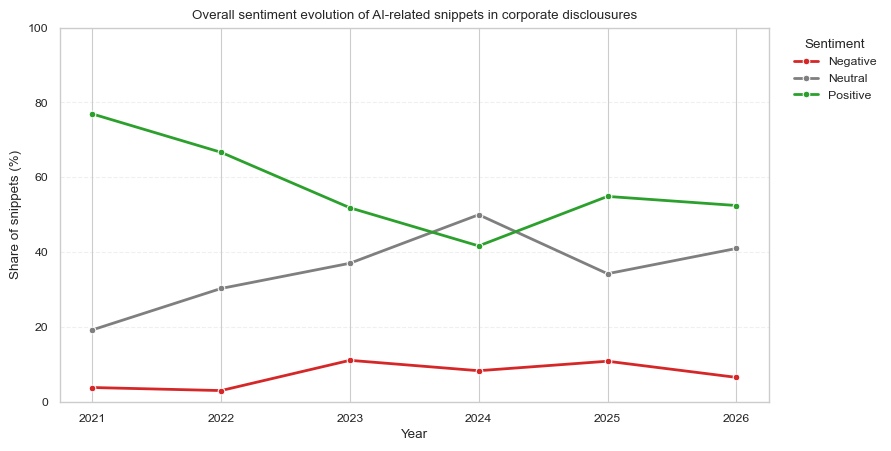

In [11]:
sns.set_theme(style='whitegrid', context='paper')
palette = {'Negative': '#d62728', 'Neutral': '#7f7f7f', 'Positive': '#2ca02c'}

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.lineplot(
    data=sent_overall_year,
    x='year', y='share_pct',
    hue='sentiment',
    hue_order=sentiment_order,
    marker='o', linewidth=2,
    palette=palette,
    ax=ax
)
ax.set_title('Overall sentiment evolution of AI-related snippets in corporate disclousures')
ax.set_xlabel('Year')
ax.set_ylabel('Share of snippets (%)')
ax.set_ylim(0, 100)
ax.legend(title='Sentiment', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

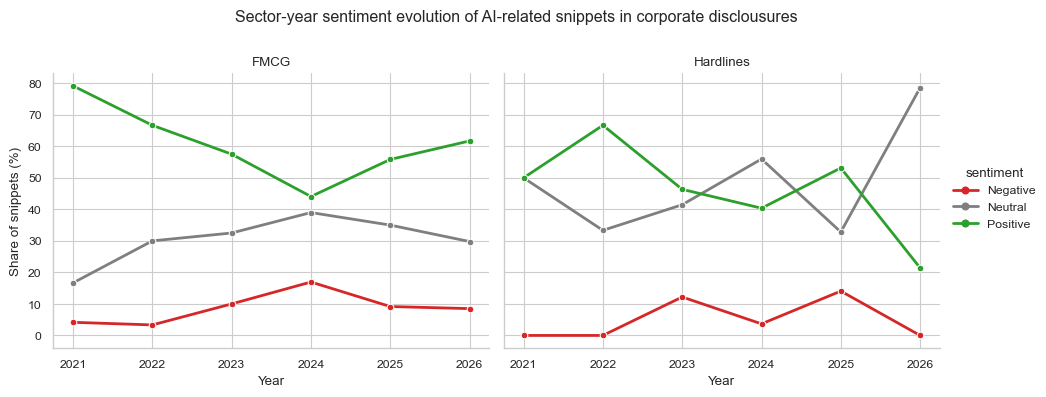

In [12]:
g = sns.relplot(
    data=sent_sector_year,
    x='year', y='share_pct',
    hue='sentiment',
    hue_order=sentiment_order,
    col='sector',
    kind='line', marker='o',
    linewidth=2,
    palette=palette,
    height=4, aspect=1.2
)
g.set_axis_labels('Year', 'Share of snippets (%)')
g.set_titles('{col_name}')
g.figure.subplots_adjust(top=0.82)
g.figure.suptitle('Sector-year sentiment evolution of AI-related snippets in corporate disclousures')
plt.show()

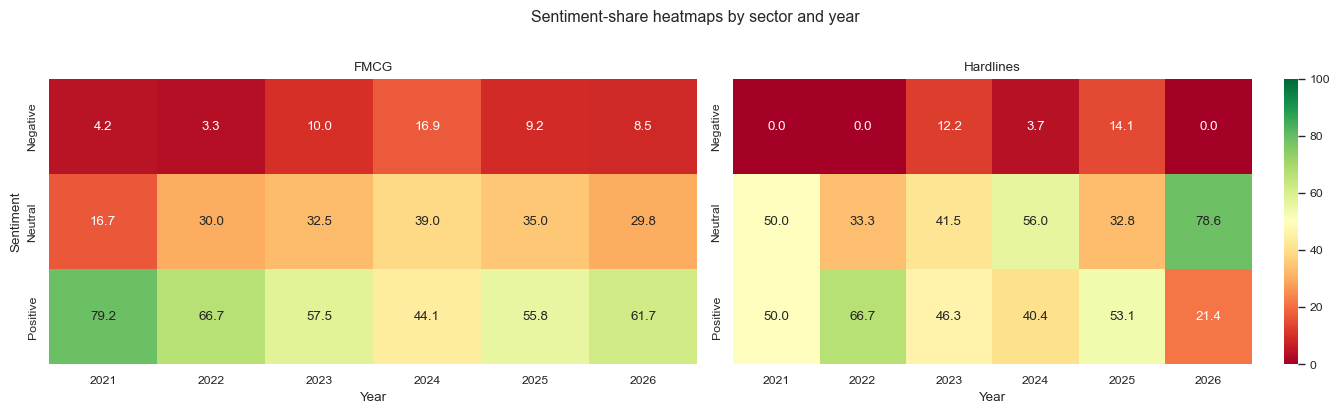

In [13]:
sectors = sorted(sent_sector_year['sector'].unique())
fig, axes = plt.subplots(1, len(sectors), figsize=(7 * len(sectors), 4), squeeze=False)

for i, sec in enumerate(sectors):
    tmp = sent_sector_year[sent_sector_year['sector'] == sec]
    heat = tmp.pivot(index='sentiment', columns='year', values='share_pct').reindex(sentiment_order)
    sns.heatmap(
        heat, annot=True, fmt='.1f', cmap='RdYlGn',
        vmin=0, vmax=100, cbar=(i == len(sectors) - 1),
        ax=axes[0, i]
    )
    axes[0, i].set_title(sec)
    axes[0, i].set_xlabel('Year')
    axes[0, i].set_ylabel('Sentiment' if i == 0 else '')

fig.suptitle('Sentiment-share heatmaps by sector and year', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Export outputs
OUT_SNIPPETS = ROOT / 'data' / 'snippets_with_sentiment.csv'
OUT_OVERALL = ROOT / 'data' / 'sentiment_overall_year.csv'
OUT_SECTOR = ROOT / 'data' / 'sentiment_sector_year.csv'

df.to_csv(OUT_SNIPPETS, index=False)
sent_overall_year.to_csv(OUT_OVERALL, index=False)
sent_sector_year.to_csv(OUT_SECTOR, index=False)

print('Saved:')
print(OUT_SNIPPETS)
print(OUT_OVERALL)
print(OUT_SECTOR)